# London collision spatial validation

Validate boundary inputs and collision membership before choosing the final borough and study period. The [research framework](../README.md#research-framework) defines the questions; this notebook supplies validation evidence and spatial visualisation rather than hotspot results. National candidates remain available so recorded codes do not determine which locations can be investigated.

**Status:** the saved validation run completed all eight code cells without errors, including the existing-output skip path. The export cell now also checks stored input hashes and awaits execution of that revision; the seven preceding cells retain their saved results. Longitude/latitude agreement, temporal boundary suitability and the final study scope remain unresolved.

## Task 3: Spatial validation

### 3.1 Inputs, parameters and provenance

Run from `notebooks/` after installing the documented dependencies and running notebook 01 to create its candidate CSV. Verify the boundary and guide against the manifest, and record the candidate CSV checksum for this run. Downloads and notebook execution are separate actions; this notebook makes no network requests.

In [1]:
from pathlib import Path
import hashlib
import json
import os
from importlib.metadata import version
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display
from pyproj import CRS, network
from pyproj.transformer import TransformerGroup

DATA_DIR = Path(os.environ.get("COMP1890_DATA_DIR", "../data")).expanduser()
BOUNDARY_PATH = Path(os.environ.get(
    "COMP1890_BOUNDARY_PATH", str(DATA_DIR / "ons-lad-december-2024-uk-bfe.gpkg")
)).expanduser()
CANDIDATE_PATH = DATA_DIR / "derived/pedestrian_collision_candidates.csv"
GUIDE_PATH = DATA_DIR / "dft-road-casualty-statistics-road-safety-open-dataset-data-guide-2025.xlsx"
OUTPUT_DIR = Path(os.environ.get(
    "COMP1890_VALIDATION_OUTPUT_DIR", str(DATA_DIR / "derived/spatial_validation")
)).expanduser()
BOUNDARY_LAYER = "LAD_DEC_24_UK_BFE"
CODE, NAME = "LAD24CD", "LAD24NM"
GRID_CRS = "EPSG:27700"
# Keep unset until documentary evidence and a tolerance rationale are available.
GEOGRAPHIC_CRS = None
GEOGRAPHIC_CRS_EVIDENCE = ""
COORDINATE_TOLERANCE_M = None
TOLERANCE_RATIONALE = ""
network.set_network_enabled(False)
versions = {name: version(name) for name in (
    "pandas", "geopandas", "shapely", "pyproj", "pyogrio", "matplotlib"
)}
display(pd.Series(versions, name="installed_version"))
manifest_path = DATA_DIR / "download-manifest.json"
for path in [BOUNDARY_PATH, CANDIDATE_PATH, GUIDE_PATH, manifest_path]:
    if not path.is_file():
        raise FileNotFoundError(f"Required input missing: {path}. Check the documented input parameters.")
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
entries = {entry["file"]: entry for entry in manifest["files"]}
input_hashes = {}
for label, path in {"boundary": BOUNDARY_PATH, "guide": GUIDE_PATH, "candidates": CANDIDATE_PATH}.items():
    with path.open("rb") as handle:
        digest = hashlib.file_digest(handle, "sha256").hexdigest()
    input_hashes[label] = digest
    if label != "candidates":
        entry = entries.get(path.name)
        if entry is None or path.stat().st_size != entry["bytes"] or digest != entry["sha256"]:
            raise ValueError(f"Input differs from its manifest entry: {path.name}")
display(pd.Series(input_hashes, name="sha256"))

pandas         3.1.1
geopandas      1.2.0
shapely        2.2.0
pyproj         3.8.0
pyogrio       0.13.0
matplotlib    3.11.2
Name: installed_version, dtype: str

boundary      a421a026170391ade115e7424b8c4e06e682e0290978b8...
guide         51b08606ef3dad1ae5d4c8726241b022fc8e4bbdc910ef...
candidates    6599e3a378f930db908b225c5b554c624ee94159a5f419...
Name: sha256, dtype: str

**Findings:** the environment reports GeoPandas 1.2.0, Shapely 2.2.0, pyproj 3.8.0 and pyogrio 0.13.0. Boundary and guide verification passed, and the candidate CSV checksum was recorded for this run. Checksums identify the input versions; they do not establish geographic accuracy.

### 3.2 Boundary geometry and district reconciliation

Select London features from the full-resolution layer and verify the CRS, codes, polygon types and geometry validity against the guide. Report positive-area overlaps without silently repairing or simplifying the source polygons. Full-resolution allocation follows [ONS guidance](../references.md#r04); the December 2024 vintage is a fixed reference geography whose temporal suitability still needs review.

In [2]:
london = gpd.read_file(
    BOUNDARY_PATH, layer=BOUNDARY_LAYER, where=f"{CODE} LIKE 'E09%'", engine="pyogrio"
)
if london.crs is None:
    raise ValueError("Boundary CRS is missing; do not infer it from coordinate values.")
source_boundary_crs = london.crs.to_string()
if not {CODE, NAME}.issubset(london.columns):
    raise ValueError("The selected layer lacks the documented district fields.")
london = london[[CODE, NAME, "geometry"]].sort_values(CODE).reset_index(drop=True)
if len(london) != 33 or london[CODE].isna().any() or not london[CODE].is_unique:
    raise ValueError("Expected 33 unique London district codes, including City of London.")
if (london.geometry.isna().any() or london.geometry.is_empty.any()
        or not london.geom_type.isin(["Polygon", "MultiPolygon"]).all()
        or not london.geometry.is_valid.all()):
    raise ValueError("Missing, empty, invalid or non-polygon boundaries require investigation; no automatic repair applied.")
london = london.to_crs(GRID_CRS)
guide = pd.read_excel(GUIDE_PATH, sheet_name="2024_code_list", dtype=str,
                     keep_default_na=False, engine="openpyxl")
guide_london = guide.loc[
    guide["table"].eq("collision") & guide["field name"].eq("local_authority_ons_district")
    & guide["code/format"].str.fullmatch(r"E090000[0-9]{2}"),
    ["code/format", "label"],
].drop_duplicates()
if guide_london["code/format"].duplicated().any() or set(guide_london["code/format"]) != set(london[CODE]):
    raise ValueError("Boundary codes do not reconcile uniquely with the supplied guide.")
name_check = london[[CODE, NAME]].merge(guide_london, left_on=CODE, right_on="code/format")
name_check["name_agrees"] = name_check[NAME].str.casefold().eq(name_check["label"].str.casefold())
overlap_rows = []
pairs = gpd.sjoin(london[["geometry"]], london[["geometry"]], predicate="intersects", how="inner")
for left, right in zip(pairs.index, pairs["index_right"], strict=True):
    if left < right:
        area = london.geometry.iloc[left].intersection(london.geometry.iloc[right]).area
        if area > 0:
            overlap_rows.append({"code_a": london[CODE].iloc[left], "code_b": london[CODE].iloc[right],
                                 "overlap_m2": float(area)})
boundary_overlaps = pd.DataFrame(overlap_rows, columns=["code_a", "code_b", "overlap_m2"])
print("Source CRS:", source_boundary_crs, "Analysis CRS:", london.crs)
display(name_check[[CODE, NAME, "label", "name_agrees"]])
print("Positive-area boundary intersections; investigate their extent rather than auto-repairing:")
display(boundary_overlaps)

Source CRS: EPSG:27700 Analysis CRS: EPSG:27700


,LAD24CD,LAD24NM,label,name_agrees
0,E09000001,City of London,City of London,True
1,E09000002,Barking and Dagenham,Barking and Dagenham,True
2,E09000003,Barnet,Barnet,True
3,E09000004,Bexley,Bexley,True
4,E09000005,Brent,Brent,True
5,E09000006,Bromley,Bromley,True
6,E09000007,Camden,Camden,True
7,E09000008,Croydon,Croydon,True
8,E09000009,Ealing,Ealing,True
9,E09000010,Enfield,Enfield,True


Positive-area boundary intersections; investigate their extent rather than auto-repairing:


,code_a,code_b,overlap_m2


**Findings:** all 33 London district codes and names reconcile with the guide, and the polygon-type, nonempty-geometry and validity safeguards passed. Source and analysis CRS are EPSG:27700, with no positive-area intersections between distinct district geometries reported. These checks do not establish that the December 2024 boundaries are temporally suitable for every study year.

### 3.3 Collision points and coordinate agreement

Build points from the authoritative grid coordinates and retain unusable records in the audit. Geographic-coordinate comparison runs only when its CRS evidence is supplied; transformation choice and missing grids are explicit, with online grid downloads disabled. A small offset does not independently validate location accuracy, and its decision tolerance requires a documented rationale: [R02–R03](../references.md#r02), [R08](../references.md#r08).

In [3]:
candidates = pd.read_csv(CANDIDATE_PATH, dtype=str, keep_default_na=False, encoding="utf-8-sig")
required = {"collision_index", "source_file_year", "local_authority_ons_district",
            "location_easting_osgr", "location_northing_osgr", "longitude", "latitude"}
if not required.issubset(candidates.columns):
    raise ValueError("Candidate CSV lacks required validation fields; recreate it with notebook 01.")
if candidates.empty or candidates["collision_index"].str.strip().eq("").any() or not candidates["collision_index"].is_unique:
    raise ValueError("Candidates must contain nonblank, unique collision IDs.")
audit = candidates.copy()
east = pd.to_numeric(audit["location_easting_osgr"], errors="coerce")
north = pd.to_numeric(audit["location_northing_osgr"], errors="coerce")
grid_usable = east.between(0, 700000, inclusive="neither") & north.between(0, 1300000, inclusive="neither")
if not grid_usable.any():
    raise ValueError("No usable grid coordinates are available.")
points = gpd.GeoDataFrame(audit.loc[grid_usable, ["collision_index"]].copy(),
    geometry=gpd.points_from_xy(east.loc[grid_usable], north.loc[grid_usable]), crs=GRID_CRS)
audit["is_recorded_london"] = audit["local_authority_ons_district"].isin(london[CODE])
audit["is_heathrow"] = audit["local_authority_ons_district"].eq("EHEATHROW")
audit["coordinate_offset_m"] = np.nan
audit["flag_grid_lonlat_disagree"] = pd.Series(pd.NA, index=audit.index, dtype="boolean")
coordinate_method = {"status": "not_checked", "reason": "Geographic CRS evidence is not configured."}
if GEOGRAPHIC_CRS is not None:
    if not GEOGRAPHIC_CRS_EVIDENCE.strip() or not CRS.from_user_input(GEOGRAPHIC_CRS).is_geographic:
        raise ValueError("Supply documentary evidence for a geographic CRS before comparison.")
    if COORDINATE_TOLERANCE_M is not None and (
        not np.isfinite(COORDINATE_TOLERANCE_M) or COORDINATE_TOLERANCE_M <= 0 or not TOLERANCE_RATIONALE.strip()
    ):
        raise ValueError("A finite positive tolerance and documented rationale are required.")
    group = TransformerGroup(GEOGRAPHIC_CRS, GRID_CRS, always_xy=True, allow_ballpark=False)
    if not group.best_available or not group.transformers:
        raise ValueError("The best transformation is unavailable offline; inspect missing grids rather than silently falling back.")
    transformer = group.transformers[0]
    lon = pd.to_numeric(audit["longitude"], errors="coerce")
    lat = pd.to_numeric(audit["latitude"], errors="coerce")
    compare = grid_usable & lon.between(-180, 180) & lat.between(-90, 90) & ~(lon.eq(0) & lat.eq(0))
    if compare.any():
        x, y = transformer.transform(lon.loc[compare].to_numpy(), lat.loc[compare].to_numpy(), errcheck=True)
        offsets = np.hypot(x - east.loc[compare].to_numpy(), y - north.loc[compare].to_numpy())
        if not np.isfinite(offsets).all():
            raise ValueError("Coordinate transformation produced non-finite offsets.")
        audit.loc[compare, "coordinate_offset_m"] = offsets
        if COORDINATE_TOLERANCE_M is not None:
            audit.loc[compare, "flag_grid_lonlat_disagree"] = offsets > COORDINATE_TOLERANCE_M
    coordinate_method = {"status": "offsets_calculated" if compare.any() else "not_checked",
        "source_crs": str(GEOGRAPHIC_CRS), "source_evidence": GEOGRAPHIC_CRS_EVIDENCE,
        "operation": transformer.description, "pipeline": transformer.definition,
        "accuracy_m": transformer.accuracy, "tolerance_m": COORDINATE_TOLERANCE_M,
        "tolerance_rationale": TOLERANCE_RATIONALE, "compared_rows": int(compare.sum())}
display(pd.Series(coordinate_method, name="coordinate_method"))
display(audit["coordinate_offset_m"].describe(percentiles=[0.5, 0.95]))
print("National candidates:", len(audit), "Unusable grid pairs:", int((~grid_usable).sum()))

status                                   not_checked
reason    Geographic CRS evidence is not configured.
Name: coordinate_method, dtype: str

count    0.0
mean     NaN
std      NaN
min      NaN
50%      NaN
95%      NaN
max      NaN
Name: coordinate_offset_m, dtype: float64

National candidates: 74682 Unusable grid pairs: 7


**Findings:** 74,675 of the 74,682 national candidates have usable grid pairs, while seven remain unusable and are retained in the audit. Geographic-coordinate agreement was not checked because its CRS evidence is unconfigured, so no offsets or disagreement decisions were calculated. The empty offset summary represents an unperformed check, not zero positional error.

### 3.4 Interior, boundary and multiple memberships

Compare all usable national points with the 33 London districts rather than filtering on recorded codes. Use strict `within` membership and a separate `intersects` join to expose boundary cases and multiple matches, following [lecture topology](../references.md#r09) and [predicate definitions](../references.md#r07). Points outside all London polygons are expected in the national input and are not automatically errors.

In [4]:
inside = gpd.sjoin(points, london[[CODE, "geometry"]], how="left", predicate="within")
intersecting = gpd.sjoin(points, london[[CODE, "geometry"]], how="left", predicate="intersects")
within_count = inside.groupby(level=0)[CODE].count().reindex(points.index, fill_value=0)
intersect_count = intersecting.groupby(level=0)[CODE].count().reindex(points.index, fill_value=0)
audit["interior_matches"] = pd.Series(pd.NA, index=audit.index, dtype="Int64")
audit["intersecting_matches"] = pd.Series(pd.NA, index=audit.index, dtype="Int64")
audit.loc[grid_usable, "interior_matches"] = within_count
audit.loc[grid_usable, "intersecting_matches"] = intersect_count
audit["membership_status"] = "invalid_grid"
audit.loc[grid_usable, "membership_status"] = "multiple_or_inconsistent"
audit.loc[grid_usable & audit["interior_matches"].eq(0) & audit["intersecting_matches"].eq(0), "membership_status"] = "outside_london"
audit.loc[grid_usable & audit["interior_matches"].eq(0) & audit["intersecting_matches"].gt(0), "membership_status"] = "boundary_touch"
unique = grid_usable & audit["interior_matches"].eq(1) & audit["intersecting_matches"].eq(1)
audit.loc[unique, "membership_status"] = "unique_interior"
audit["geometric_london_code"] = ""
first_code = inside.groupby(level=0)[CODE].first()
audit.loc[unique, "geometric_london_code"] = first_code.reindex(audit.index[unique])
matched_codes = intersecting.dropna(subset=[CODE]).groupby(level=0)[CODE].agg(
    lambda codes: ";".join(sorted(set(codes))))
audit["intersecting_london_codes"] = audit.index.to_series().map(matched_codes).fillna("")
assert audit["collision_index"].is_unique and len(audit) == len(candidates)
display(pd.crosstab(audit["membership_status"], audit["is_recorded_london"],
                    colnames=["recorded_London"], margins=True))

recorded_London,False,True,All
membership_status,,,
invalid_grid,7,0,7
outside_london,57062,0,57062
unique_interior,17,17596,17613
All,57086,17596,74682


**Findings:** 17,613 collisions have unique London interior membership: all 17,596 recorded-London events plus 17 events with other recorded codes. No boundary-touching, multiple-match or unresolved recorded-London cases are reported; the seven unusable-grid records are outside the recorded-London subset. The other 57,062 usable national points lie outside the London polygons and are not automatically data errors.

### 3.5 Recorded codes, Heathrow and selection evidence

Compare recorded and geometric districts only where membership is uniquely resolved. Retain Heathrow as its own recorded category and show where its points fall without assuming Hillingdon membership. The borough evidence table describes candidate counts, not exposure-adjusted risk or a final borough decision.

In [5]:
audit["flag_recorded_code_disagrees"] = pd.Series(pd.NA, index=audit.index, dtype="boolean")
audit.loc[unique, "flag_recorded_code_disagrees"] = audit.loc[unique, "local_authority_ons_district"].ne(
    audit.loc[unique, "geometric_london_code"])
relevant = audit["is_recorded_london"] | audit["is_heathrow"] | audit["intersecting_matches"].fillna(0).gt(0)
recorded_label = audit["local_authority_ons_district"].replace("", "[blank]")
geometric_label = audit["geometric_london_code"].where(unique, audit["membership_status"])
comparison = pd.crosstab(recorded_label.loc[relevant], geometric_label.loc[relevant])
issue = relevant & (~unique | audit["flag_recorded_code_disagrees"].fillna(False))
issue_columns = ["collision_index", "local_authority_ons_district", "geometric_london_code",
                 "membership_status", "interior_matches", "intersecting_matches", "intersecting_london_codes"]
print("Membership/code-disagreement cases (first 20; complete audit exported later)")
display(audit.loc[issue, issue_columns].head(20))
print("Heathrow recorded events; geometric membership is evaluated independently")
display(audit.loc[audit["is_heathrow"], issue_columns])
assigned = audit.loc[unique]
borough_summary = london[[CODE, NAME]].copy()
for year in sorted(audit["source_file_year"].unique()):
    counts = assigned.loc[assigned["source_file_year"].eq(year), "geometric_london_code"].value_counts()
    borough_summary[year] = borough_summary[CODE].map(counts).fillna(0).astype(int)
borough_summary["geometric_total"] = borough_summary[CODE].map(
    assigned["geometric_london_code"].value_counts()).fillna(0).astype(int)
borough_summary["recorded_total"] = borough_summary[CODE].map(
    audit["local_authority_ons_district"].value_counts()).fillna(0).astype(int)
borough_summary["code_disagreements"] = borough_summary[CODE].map(
    audit.loc[audit["flag_recorded_code_disagrees"].fillna(False), "geometric_london_code"].value_counts()
).fillna(0).astype(int)
borough_summary["heathrow_events"] = borough_summary[CODE].map(
    assigned.loc[assigned["is_heathrow"], "geometric_london_code"].value_counts()).fillna(0).astype(int)
borough_summary = borough_summary.sort_values("geometric_total", ascending=False)
display(borough_summary)
print("The complete recorded/geometric cross-tabulation will be exported; unresolved cases are excluded from geometric borough totals.")

Membership/code-disagreement cases (first 20; complete audit exported later)


,collision_index,local_authority_ons_district,geometric_london_code,membership_status,interior_matches,intersecting_matches,intersecting_london_codes
92,2022010354125,E09000033,E09000005,unique_interior,1,1,E09000005
95,2022010354145,E09000013,E09000020,unique_interior,1,1,E09000020
284,2022010357022,E09000033,E09000005,unique_interior,1,1,E09000005
329,2022010357653,E09000020,E09000033,unique_interior,1,1,E09000033
337,2022010357772,E09000027,E09000032,unique_interior,1,1,E09000032
344,2022010357859,E09000020,E09000013,unique_interior,1,1,E09000013
406,2022010358795,E09000019,E09000012,unique_interior,1,1,E09000012
472,2022010359725,E09000015,E09000005,unique_interior,1,1,E09000005
492,2022010359912,E09000022,E09000032,unique_interior,1,1,E09000032
498,2022010359969,E09000012,E09000019,unique_interior,1,1,E09000019


Heathrow recorded events; geometric membership is evaluated independently


,collision_index,local_authority_ons_district,geometric_london_code,membership_status,interior_matches,intersecting_matches,intersecting_london_codes
598,2022010361758,EHEATHROW,E09000017,unique_interior,1,1,E09000017
1916,2022010382224,EHEATHROW,E09000017,unique_interior,1,1,E09000017
21998,2023010474258,EHEATHROW,E09000017,unique_interior,1,1,E09000017
22577,2023010482196,EHEATHROW,E09000017,unique_interior,1,1,E09000017
37356,2024010490318,EHEATHROW,E09000017,unique_interior,1,1,E09000017
37835,2024010497217,EHEATHROW,E09000017,unique_interior,1,1,E09000017
38448,2024010507884,EHEATHROW,E09000017,unique_interior,1,1,E09000017
39165,2024010519251,EHEATHROW,E09000017,unique_interior,1,1,E09000017
39750,2024010529813,EHEATHROW,E09000017,unique_interior,1,1,E09000017
40473,2024010540194,EHEATHROW,E09000017,unique_interior,1,1,E09000017


,LAD24CD,LAD24NM,2022,2023,2024,2025,geometric_total,recorded_total,code_disagreements,heathrow_events
32,E09000033,Westminster,285,335,310,316,1246,1250,14,0
7,E09000008,Croydon,190,200,180,222,792,793,1,0
21,E09000022,Lambeth,203,203,164,173,743,751,5,0
24,E09000025,Newham,170,190,173,184,717,716,2,0
29,E09000030,Tower Hamlets,160,176,165,209,710,708,7,0
4,E09000005,Brent,189,153,182,170,694,691,20,0
27,E09000028,Southwark,179,182,148,180,689,680,14,0
8,E09000009,Ealing,168,147,189,171,675,672,5,0
6,E09000007,Camden,155,176,157,173,661,666,19,0
13,E09000014,Haringey,174,159,159,159,651,647,6,0


The complete recorded/geometric cross-tabulation will be exported; unresolved cases are excluded from geometric borough totals.


**Findings:** 199 uniquely assigned events have different recorded and geometric district codes, comprising 182 recorded-London district differences and 17 Heathrow-coded events inside Hillingdon. Geometric totals are 1,246 for Westminster, 792 for Croydon and 743 for Lambeth, compared with recorded totals of 1,250, 793 and 751. These differences require interpretation under the chosen boundary vintage and do not independently prove that recorded codes or coordinates are wrong.

### 3.6 London context and diagnostic maps

Show borough totals using proportional symbol areas and include a diagnostic panel when code disagreements, ambiguous memberships or Heathrow points are present. Use colour categories for diagnostic cases and distinguish mapped records from cases without usable coordinates, following [lecture map design](../references.md#r10). These maps describe counts and validation cases; symbol sizes and point overlap do not establish risk or statistical hotspots.

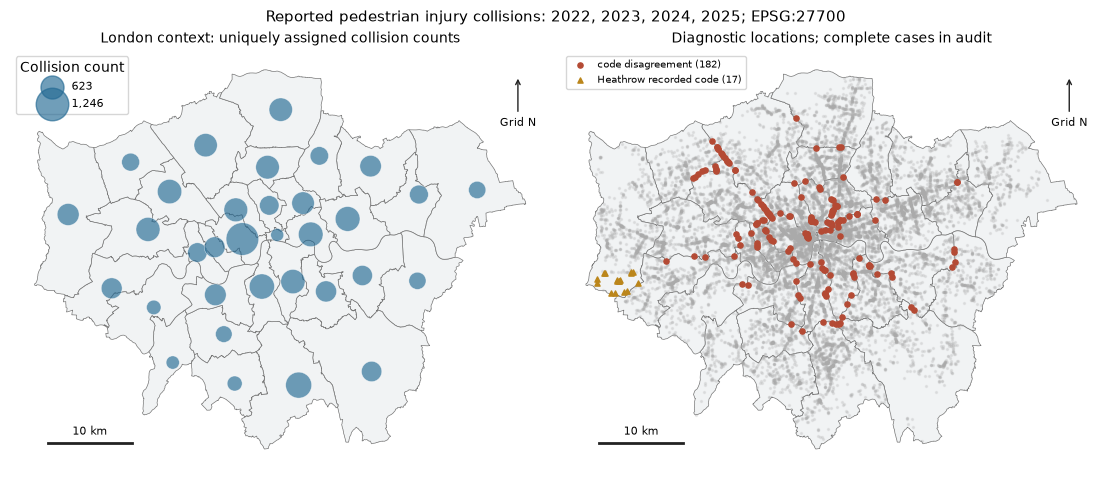

Sources: DfT collisions/casualties; ONS December 2024 BFE boundaries. See references R01/R05/R06.
Geometric totals exclude unresolved memberships; unusable-coordinate cases are retained in the audit.
Before report reuse, add the product-specific ONS/OS attribution and check the layout in QGIS.


In [6]:
map_data = london.merge(borough_summary[[CODE, "geometric_total"]], on=CODE, how="left")
anchors = map_data.geometry.representative_point()
diagnostic_index = audit.index[grid_usable & (issue | audit["is_heathrow"])]
show_diagnostic = len(diagnostic_index) > 0
fig, axes = plt.subplots(1, 2 if show_diagnostic else 1,
                         figsize=(11, 4.8) if show_diagnostic else (6, 5),
                         layout="constrained", squeeze=False)
ax = axes[0, 0]
map_data.plot(ax=ax, facecolor="#f1f3f4", edgecolor="#777777", linewidth=0.5)
maximum = max(int(map_data["geometric_total"].max()), 1)
ax.scatter(anchors.x, anchors.y, s=map_data["geometric_total"] / maximum * 550,
           color="#246A94", alpha=0.65, edgecolors="white", linewidths=0.4)
legend_values = sorted(set([maximum, max(1, maximum // 2)]))
handles = [ax.scatter([], [], s=value / maximum * 550, color="#246A94", alpha=0.65,
                      label=f"{value:,}") for value in legend_values]
ax.legend(handles=handles, title="Collision count", loc="upper left", frameon=True, fontsize=8)
ax.set_title("London context: uniquely assigned collision counts", fontsize=10)
if show_diagnostic:
    ax = axes[0, 1]
    london.plot(ax=ax, facecolor="#f1f3f4", edgecolor="#777777", linewidth=0.5)
    background_index = audit.index[grid_usable & relevant]
    points.loc[background_index].plot(ax=ax, color="#aaaaaa", markersize=2, alpha=0.2)
    categories = pd.Series("code disagreement", index=diagnostic_index)
    unresolved_index = audit.index[grid_usable & relevant & ~unique]
    categories.loc[categories.index.intersection(unresolved_index)] = "unresolved membership"
    # The table retains both attributes when a Heathrow point is also a disagreement.
    heathrow_index = audit.index[grid_usable & audit["is_heathrow"]]
    categories.loc[categories.index.intersection(heathrow_index)] = "Heathrow recorded code"
    for label, colour, marker in [
        ("code disagreement", "#b44a34", "o"),
        ("unresolved membership", "#76518c", "x"),
        ("Heathrow recorded code", "#bb861b", "^")
    ]:
        indices = categories.index[categories.eq(label)]
        if len(indices):
            points.loc[indices].plot(ax=ax, color=colour, marker=marker, markersize=14,
                                     label=f"{label} ({len(indices):,})")
    ax.legend(loc="upper left", fontsize=7)
    ax.set_title("Diagnostic locations; complete cases in audit", fontsize=10)
for ax in axes.flat:
    ax.set_aspect("equal", adjustable="box")
    ax.set_axis_off()
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    x0, y0 = xmin + (xmax-xmin)*0.07, ymin + (ymax-ymin)*0.06
    ax.plot([x0, x0+10000], [y0, y0], color="#222222", linewidth=2)
    ax.text(x0+5000, y0+(ymax-ymin)*0.02, "10 km", ha="center", fontsize=8)
    ax.annotate("Grid N", xy=(0.94, 0.94), xytext=(0.94, 0.82),
                xycoords="axes fraction", ha="center", fontsize=8,
                arrowprops={"arrowstyle": "->", "color": "#222222"})
period_label = ", ".join(sorted(audit["source_file_year"].unique()))
fig.suptitle(f"Reported pedestrian injury collisions: {period_label}; EPSG:27700", fontsize=11)
plt.show()
print("Sources: DfT collisions/casualties; ONS December 2024 BFE boundaries. See references R01/R05/R06.")
print("Geometric totals exclude unresolved memberships; unusable-coordinate cases are retained in the audit.")
print("Before report reuse, add the product-specific ONS/OS attribution and check the layout in QGIS.")

**Findings:** the saved two-panel figure shows geometric borough totals and diagnostic locations, with 182 district-code differences and 17 Heathrow-coded events represented separately. No unresolved-membership category appears because none was found among mapped relevant events. Point overlap can conceal individual events, and the figure describes validation cases rather than statistical hotspots; final attribution and QGIS layout review remain pending.

### 3.7 Audit summary and unresolved decisions

Summarise evaluated membership checks separately from coordinate checks that remain unknown. Keep the selected-borough membership flag unresolved because no borough has been chosen. Temporal boundary suitability, the final period and the statistical method remain explicit decisions.

In [7]:
metrics = {
    "national_candidates": len(audit),
    "usable_grid_pairs": int(grid_usable.sum()),
    "unusable_grid_pairs": int((~grid_usable).sum()),
    "unique_london_interior": int(unique.sum()),
    "boundary_touch": int(audit["membership_status"].eq("boundary_touch").sum()),
    "multiple_or_inconsistent": int(audit["membership_status"].eq("multiple_or_inconsistent").sum()),
    "recorded_london_unresolved": int((audit["is_recorded_london"] & ~unique).sum()),
    "unique_membership_code_disagreements": int(audit["flag_recorded_code_disagrees"].sum()),
    "heathrow_recorded_events": int(audit["is_heathrow"].sum()),
    "coordinate_agreement_checked_rows": int(audit["flag_grid_lonlat_disagree"].notna().sum()),
    "positive_area_boundary_pairs": len(boundary_overlaps),
}
validation_summary = pd.Series(metrics, name="count")
display(validation_summary)
audit["spatial_validation_status"] = "london_membership_evaluated_final_scope_pending"
audit.loc[~grid_usable, "spatial_validation_status"] = "unusable_grid_membership_not_checked"
run_metadata = {"executed_utc": datetime.now(timezone.utc).isoformat(), "versions": versions,
    "input_sha256": input_hashes, "boundary_vintage": "December 2024",
    "source_boundary_crs": source_boundary_crs, "analysis_crs": GRID_CRS,
    "coordinate_method": coordinate_method, "metrics": metrics,
    "temporal_suitability": "not_checked", "selected_borough": None, "final_period": None,
    "boundary_rule": "Assign only exactly one within and one intersects match; retain all other cases for review."}
print("No borough selected and no final spatial exclusions applied. Coordinate agreement status:", coordinate_method["status"])

national_candidates                     74682
usable_grid_pairs                       74675
unusable_grid_pairs                         7
unique_london_interior                  17613
boundary_touch                              0
multiple_or_inconsistent                    0
recorded_london_unresolved                  0
unique_membership_code_disagreements      199
heathrow_recorded_events                   17
coordinate_agreement_checked_rows           0
positive_area_boundary_pairs                0
Name: count, dtype: int64

No borough selected and no final spatial exclusions applied. Coordinate agreement status: not_checked


**Findings:** the audit reports 199 recorded/geometric code differences, no positive-area district overlaps and no unresolved recorded-London memberships. Coordinate agreement has zero evaluated rows and remains `not_checked`; temporal suitability is also unresolved. No borough or final period has been selected, and no final spatial exclusions or hotspot tests have been applied.

### 3.8 Validation exports for inspection and QGIS

Export the complete national audit, borough evidence, recorded/geometric cross-tabulation, overlap audit and run metadata. The GeoPackage contains London boundaries and usable points relevant by geometry, recorded-London code or Heathrow code; invalid-coordinate records remain in the CSV audit. If any named output exists, skip all writes and report file completeness and whether stored input hashes match; a hash match does not verify code or artifact contents.

In [8]:
outputs = {name: OUTPUT_DIR / name for name in [
    "london_validation.gpkg", "collision_validation_audit.csv", "borough_selection_evidence.csv",
    "recorded_geometric_comparison.csv", "boundary_overlaps.csv", "validation_run.json"
]}
input_paths = {p.resolve() for p in [BOUNDARY_PATH, CANDIDATE_PATH, GUIDE_PATH, manifest_path]}
if any(path.resolve() in input_paths for path in outputs.values()):
    raise ValueError("Output path conflicts with an input.")
existing_outputs = [name for name, path in outputs.items() if path.exists()]
if existing_outputs:
    print("Export skipped: output files already exist in", OUTPUT_DIR)
    print("Existing files:", existing_outputs)
    missing_outputs = [name for name in outputs if name not in existing_outputs]
    if missing_outputs:
        print("Output set is incomplete; missing files:", missing_outputs)
    try:
        stored_metadata = json.loads(outputs["validation_run.json"].read_text(encoding="utf-8"))
        if not isinstance(stored_metadata, dict):
            raise ValueError("Stored metadata is not an object.")
        stored_hashes = stored_metadata.get("input_sha256")
        if not isinstance(stored_hashes, dict) or set(stored_hashes) != set(input_hashes):
            print("Input provenance: unverifiable (stored input hashes are incomplete).")
        elif stored_hashes == input_hashes:
            print("Input provenance: match. This does not verify code, settings or exported artifact contents.")
        else:
            print("Input provenance: mismatch. Existing exports belong to different inputs.")
    except (OSError, ValueError):
        print("Input provenance: unverifiable (stored run metadata is missing or unreadable).")
    print("Existing files were retained; they were not regenerated from this execution.")
    print("To save current results separately, choose a new COMP1890_VALIDATION_OUTPUT_DIR.")
else:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    export_columns = ["collision_index", "source_file_year", "local_authority_ons_district",
        "geometric_london_code", "membership_status", "interior_matches", "intersecting_matches",
        "flag_recorded_code_disagrees", "is_heathrow", "coordinate_offset_m", "flag_grid_lonlat_disagree"]
    export_index = audit.index[grid_usable & relevant]
    export_points = gpd.GeoDataFrame(audit.loc[export_index, export_columns].copy(),
                                   geometry=points.geometry.reindex(export_index), crs=GRID_CRS)
    london.to_file(outputs["london_validation.gpkg"], layer="london_boundaries", driver="GPKG", engine="pyogrio")
    if not export_points.empty:
        export_points.to_file(outputs["london_validation.gpkg"], layer="collision_validation", driver="GPKG", engine="pyogrio", mode="a")
    audit.to_csv(outputs["collision_validation_audit.csv"], index=False)
    borough_summary.to_csv(outputs["borough_selection_evidence.csv"], index=False)
    comparison.to_csv(outputs["recorded_geometric_comparison.csv"])
    boundary_overlaps.to_csv(outputs["boundary_overlaps.csv"], index=False)
    outputs["validation_run.json"].write_text(json.dumps(run_metadata, indent=2)+"\n", encoding="utf-8")
    print("Exported validation evidence:", [path.name for path in outputs.values()])
    print("QGIS layers: london_boundaries and, when nonempty, collision_validation. CRS: EPSG:27700.")


Export skipped: output files already exist in ../data/derived/spatial_validation
Existing files: ['london_validation.gpkg', 'collision_validation_audit.csv', 'borough_selection_evidence.csv', 'recorded_geometric_comparison.csv', 'boundary_overlaps.csv', 'validation_run.json']
Input provenance: match. This does not verify code, settings or exported artifact contents.
Existing files were retained; they were not regenerated from this execution.
To save current results separately, choose a new COMP1890_VALIDATION_OUTPUT_DIR.


**Export status:** the previous saved execution skipped existing files successfully; the input-provenance revision has not yet been run. Existing files are retained, with input hashes reported as matching, mismatching or unverifiable and any missing outputs listed. Use a new output directory to save current results separately; QGIS inspection and report screenshots remain pending.